# 实验作业

## 1. NetCDF格式数据处理

**目标：**
- 掌握NetCDF格式数据的基本处理方法。

**数据：**
- 矢量数据，其中包括城市数据（./data/ChinaMap/cities.shp）和分省数据（./data/ChinaMap/provinces.shp）
- 中国区域地面气象要素驱动数据集（逐日降水数据： ./data/CMFD/prec_CMFD_V0200_B-01_01dy_010deg_202401-202412.nc）

**实验要求：**
- 根据下面的“研究区分配方案”选择自己的研究区，分析对应的省份（包括省内的城市）覆盖区域的降水情况（2024年）。
- 计算研究区（以省/自治区为单位）2024年全年总降水量和逐月总降水量的空间分布情况，分别保存为GeoTIFF和netCDF格式，并绘制地图。
- 利用clip方法得到研究区内各个地市覆盖区域的降水数据，并分别保存为GeoTIFF和netCDF格式数据；利用得到的nc数据，计算各个地市的年总降水量，并按照从低至高的顺序排序。

**研究区分配方案：**

| 序号 | 班级     | 学号        | 姓名   | 省份               |
|------|----------|-------------|--------|--------------------|
| 1    | 遥感23-1 | 2023b48001  | 吴光耀 | 浙江省             |
| 2    | 遥感23-1 | 2023b48007  | 牛荦荦 | 江苏省             |
| 3    | 遥感23-1 | 2023b48008  | 陈家乐 | 广东省             |
| 4    | 遥感23-1 | 2023b48009  | 赵悦辰 | 山东省             |
| 5    | 遥感23-1 | 2023b48017  | 裘毅   | 河南省             |
| 6    | 遥感23-1 | 2023b48018  | 杨忆真 | 河北省             |
| 7    | 遥感23-1 | 2023b48019  | 陈一诺 | 湖南省             |
| 8    | 遥感23-1 | 2023b48020  | 朱宇浩 | 湖北省             |
| 9    | 遥感23-1 | 2023b48025  | 孟泽杭 | 安徽省             |
| 10   | 遥感23-1 | 2023b48028  | 胡俊璘 | 福建省             |
| 11   | 遥感23-1 | 2023b48040  | 刘世鑫 | 江西省             |
| 12   | 遥感23-2 | 2023b48041  | 雷少杰 | 四川省             |
| 13   | 遥感23-2 | 2023b48046  | 张云瑾 | 云南省             |
| 14   | 遥感23-2 | 2023b48047  | 叶琳萱 | 贵州省             |
| 15   | 遥感23-2 | 2023b48054  | 金军臻 | 广西壮族自治区     |
| 16   | 遥感23-2 | 2023b48055  | 周文睿 | 陕西省             |
| 17   | 遥感23-2 | 2023b48056  | 朱可力 | 甘肃省             |
| 18   | 遥感23-2 | 2023b48058  | 王诗燚 | 青海省             |
| 19   | 遥感23-2 | 2023b48061  | 傅宇恒 | 山西省             |
| 20   | 遥感23-2 | 2023b48063  | 应鸣   | 辽宁省             |
| 21   | 遥感23-2 | 2023b48066  | 陈畅   | 吉林省             |
| 22   | 遥感23-2 | 2023b48067  | 翁艺翎 | 黑龙江省           |
| 23   | 遥感23-2 | 2023b48072  | 邹黎妮 | 海南省             |
| 24   | 遥感23-2 | 2023b48074  | 蔡瑞欣 | 内蒙古自治区       |
| 25   | 遥感23-2 | 2023b48075  | 张兴政 | 宁夏回族自治区     |
| 26   | 遥感23-2 | 2023b48076  | 陈展亦 | 新疆维吾尔自治区   |
| 27   | 遥感23-2 | 2023b48079  | 朱永丰 | 西藏自治区         |



In [5]:
import xarray as xr

# 查看属性数据项
ds = xr.open_dataset("./data/CMFD/prec_CMFD_V0200_B-01_01dy_010deg_202401-202412.nc")
ds['prec'].attrs

{'standard_name': 'precipitation_flux',
 'long_name': 'Precipitation',
 'units': 'kg m-2 s-1'}

In [ ]:
#安装pypinyin库
pip install pypinyin

   ---------------------------------------- 0.0/840.2 kB ? eta -:--:--
   ---------------------------------------- 0.0/840.2 kB ? eta -:--:--
   ---------------------------------------- 0.0/840.2 kB ? eta -:--:--
   ---------------------------------------- 0.0/840.2 kB ? eta -:--:--
   ---------------------------------------- 0.0/840.2 kB ? eta -:--:--
   ------------ --------------------------- 262.1/840.2 kB ? eta -:--:--
   ------------ --------------------------- 262.1/840.2 kB ? eta -:--:--
   ------------ --------------------------- 262.1/840.2 kB ? eta -:--:--
   ------------ --------------------------- 262.1/840.2 kB ? eta -:--:--
   ------------ --------------------------- 262.1/840.2 kB ? eta -:--:--
   ------------ --------------------------- 262.1/840.2 kB ? eta -:--:--
   ------------ --------------------------- 262.1/840.2 kB ? eta -:--:--
   ------------ --------------------------- 262.1/840.2 kB ? eta -:--:--
   ------------ --------------------------- 262.1/840.2 kB ? 

In [ ]:
##2024年内蒙古自治区逐日的温度（单位为开尔文）
# 示例代码
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import geopandas as gpd
import rioxarray
from pypinyin import lazy_pinyin

def to_pinyin(name):
    return "_".join(lazy_pinyin(name))

# -----------------------------
# 1. 读取矢量
# -----------------------------
cities = gpd.read_file("./data/ChinaMap/cities.shp")
gdf_sel = cities[cities["省"] == "内蒙古自治区"]

# -----------------------------
# 2. 读取 nc
# -----------------------------
ds = xr.open_dataset("./data/CMFD/temp_CMFD_V0200_B-01_01dy_010deg_202401-202412.nc")

da = ds["temp"]   # 关键：选变量

# 写 CRS
da = da.rio.write_crs("EPSG:4326")

# -----------------------------
# 3. 坐标系统一（必须）
# -----------------------------
gdf_sel = gdf_sel.to_crs(da.rio.crs)

# -----------------------------
# 4. 逐城市裁剪
# -----------------------------
for city in gdf_sel.itertuples():
    city_name = city.市
    geom = city.geometry

    print(city_name)

    # 选一个时间（否则会报 TooManyDimensions）
    # da_2d = da.isel(time=0)

    # 裁剪
    clipped = da.rio.clip([geom], all_touched=True)

    # 保存为GeoTIFF
    clipped.rio.to_raster(f"./outputs/{city_name}_temp.tif")

    # 保存为 NetCDF
    city_name_safe = to_pinyin(city_name)
    clipped.to_netcdf(f"./outputs/{city_name_safe}_temp.nc")

兴安盟
呼和浩特市
包头市
锡林郭勒盟
乌海市
赤峰市
通辽市
鄂尔多斯市
阿拉善盟
呼伦贝尔市
巴彦淖尔市
乌兰察布市


In [ ]:
#netCDF文件的读写
ds = xr.open_dataset('./outputs/a_la_shan_meng_temp.nc')#读取阿拉善盟温度文件
ds

<xarray.Dataset> Size: 8MB
Dimensions:      (lat: 54, lon: 98, time: 366)
Coordinates:
  * lat          (lat) float32 216B 37.45 37.55 37.65 ... 42.55 42.65 42.75
  * lon          (lon) float32 392B 97.15 97.25 97.35 ... 106.7 106.8 106.8
  * time         (time) datetime64[ns] 3kB 2024-01-01T10:30:00 ... 2024-12-31...
Data variables:
    spatial_ref  int32 4B ...
    temp         (time, lat, lon) float32 8MB ...

In [ ]:
#查看降水量文件的属性
ds = xr.open_dataset("./data/CMFD/prec_CMFD_V0200_B-01_01dy_010deg_202401-202412.nc")
print(ds)

<xarray.Dataset> Size: 410MB
Dimensions:  (lat: 400, lon: 700, time: 366)
Coordinates:
  * lat      (lat) float32 2kB 15.05 15.15 15.25 15.35 ... 54.75 54.85 54.95
  * lon      (lon) float32 3kB 70.05 70.15 70.25 70.35 ... 139.8 139.9 139.9
  * time     (time) datetime64[ns] 3kB 2024-01-01T10:30:00 ... 2024-12-31T10:...
Data variables:
    prec     (time, lat, lon) float32 410MB ...
Attributes:
    source:       Meteorological Data Fusion System (Version: 01.02.0280)
    institution:  Institute of Tibetan Plateau Research, Chinese Academy of S...
    Conventions:  CF-1.0
    description:  Data from China Meteorological Forcing Dataset (Version: 02...
    references:   Yang, K., J. He, W. Tang, H. Lu, J. Qin, Y. Chen, X. Li, 20...
    frequency:    day
    title:        Daily mean precipitation from the China Meteorological Forc...
    history:      Created at 2025-11-28 05:35:29 UTC by the ITPCAS Data Fusio...


In [ ]:
# 获取某个变量的属性
ds["prec"].attrs
#从输出结果可以看出，表示降水量的变量为prec，单位是kg m-2 s-1，后续要注意单位转换

{'standard_name': 'precipitation_flux',
 'long_name': 'Precipitation',
 'units': 'kg m-2 s-1'}

计算内蒙古自治区2024年全年总降水量

1. 读取矢量数据...
  找到 12 个城市

2. 读取降水数据...
  原始单位: kg m-2 s-1
  时间范围: 2024-01-01T10:30:00.000000000 到 2024-12-31T10:30:00.000000000

3. 计算2024年全年总降水量...
  全区平均年降水量: 749.0 mm/year
  年降水量范围: 0.0 - 8395.6 mm/year

4. 坐标系统一...

5. 裁剪内蒙古全区范围...

6. 保存全区数据...
  ✓ GeoTIFF已保存: ./outputs/Neimenggu_annual_prec_2024.tif
  ✓ NetCDF已保存: ./outputs/Neimenggu_annual_prec_2024.nc

7. 逐城市保存数据...
  处理: 兴安盟
    ✓ GeoTIFF: ./outputs/兴安盟_annual_prec_2024.tif
    ✓ NetCDF: ./outputs/xing_an_meng_annual_prec_2024.nc
  处理: 呼和浩特市
    ✓ GeoTIFF: ./outputs/呼和浩特市_annual_prec_2024.tif
    ✓ NetCDF: ./outputs/hu_he_hao_te_shi_annual_prec_2024.nc
  处理: 包头市
    ✓ GeoTIFF: ./outputs/包头市_annual_prec_2024.tif
    ✓ NetCDF: ./outputs/bao_tou_shi_annual_prec_2024.nc
  处理: 锡林郭勒盟
    ✓ GeoTIFF: ./outputs/锡林郭勒盟_annual_prec_2024.tif
    ✓ NetCDF: ./outputs/xi_lin_guo_lei_meng_annual_prec_2024.nc
  处理: 乌海市
    ✓ GeoTIFF: ./outputs/乌海市_annual_prec_2024.tif
    ✓ NetCDF: ./outputs/wu_hai_shi_annual_prec_2024.nc
 

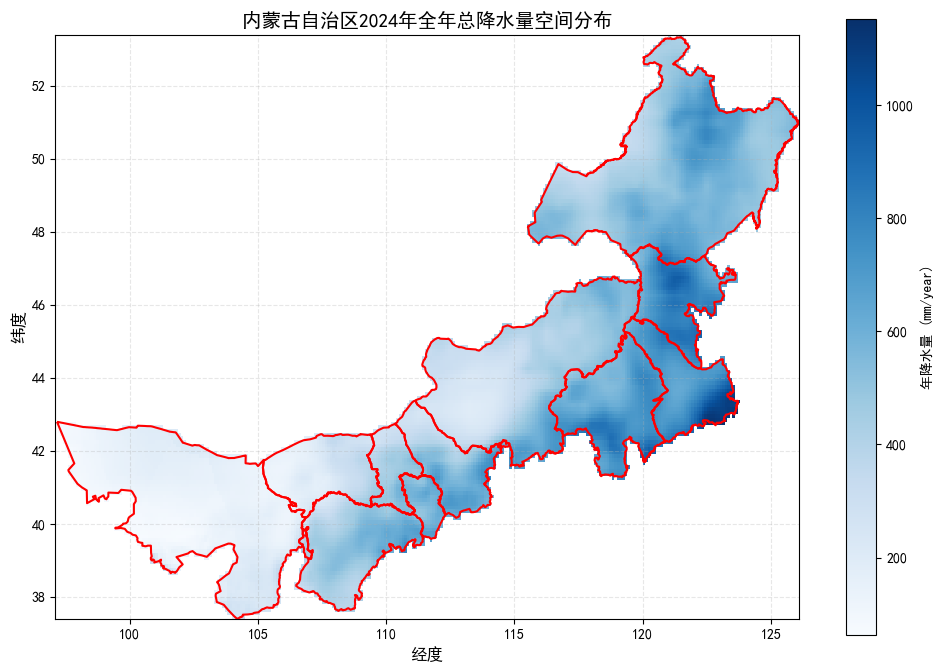


处理完成！

输出文件:
  全区数据:
    - ./outputs/Neimenggu_annual_prec_2024.tif
    - ./outputs/Neimenggu_annual_prec_2024.nc
  各城市数据:
    - ./outputs/{城市名}_annual_prec_2024.tif
    - ./outputs/{拼音}_annual_prec_2024.nc
  地图:
    - ./outputs/Neimenggu_precipitation_map.png

统计信息:
  全区平均年降水量: 455.1 mm/year
  最大年降水量: 1152.3 mm/year
  最小年降水量: 63.8 mm/year


In [21]:
# 计算内蒙古自治区2024年全年总降水量的空间分布情况
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import geopandas as gpd
import rioxarray
from pypinyin import lazy_pinyin
import os

font_path = 'C:/Windows/Fonts/simhei.ttf'  # 黑体

# 添加字体文件并设置
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'SimHei'
plt.rcParams['axes.unicode_minus'] = False

def to_pinyin(name):
    return "_".join(lazy_pinyin(name))

# 创建输出目录
os.makedirs("./outputs", exist_ok=True)

print("="*50)
print("计算内蒙古自治区2024年全年总降水量")
print("="*50)

# -----------------------------
# 1. 读取矢量数据
# -----------------------------
print("\n1. 读取矢量数据...")
cities = gpd.read_file("./data/ChinaMap/cities.shp")
gdf_sel = cities[cities["省"] == "内蒙古自治区"]
print(f"  找到 {len(gdf_sel)} 个城市")

# -----------------------------
# 2. 读取降水NC文件
# -----------------------------
print("\n2. 读取降水数据...")
ds = xr.open_dataset("./data/CMFD/prec_CMFD_V0200_B-01_01dy_010deg_202401-202412.nc")

# 选择降水变量
da = ds["prec"]
print(f"  原始单位: {da.attrs.get('units', '未指定')}")
print(f"  时间范围: {da.time.values[0]} 到 {da.time.values[-1]}")

# -----------------------------
# 3. 单位转换并计算年总降水量
# -----------------------------
print("\n3. 计算2024年全年总降水量...")

# 单位转换：kg m⁻² s⁻¹ → mm/day (乘以86400)
seconds_per_day = 24 * 3600
daily_precip = da * seconds_per_day

# 沿时间维度求和，得到年总降水量 (mm/year)
annual_total = daily_precip.sum(dim='time', skipna=True)
annual_total.attrs['units'] = 'mm/year'
annual_total.attrs['long_name'] = 'Annual Total Precipitation'

print(f"  全区平均年降水量: {annual_total.mean().values:.1f} mm/year")
print(f"  年降水量范围: {annual_total.min().values:.1f} - {annual_total.max().values:.1f} mm/year")

# 设置CRS
annual_total = annual_total.rio.write_crs("EPSG:4326")

# -----------------------------
# 4. 坐标系统一
# -----------------------------
print("\n4. 坐标系统一...")
gdf_sel = gdf_sel.to_crs(annual_total.rio.crs)

# -----------------------------
# 5. 裁剪内蒙古全区范围
# -----------------------------
print("\n5. 裁剪内蒙古全区范围...")
neimenggu_total = annual_total.rio.clip(gdf_sel.geometry, all_touched=True)

# -----------------------------
# 6. 保存内蒙古全区年总降水量
# -----------------------------
print("\n6. 保存全区数据...")

# 保存为GeoTIFF
neimenggu_total.rio.to_raster("./outputs/Neimenggu_annual_prec_2024.tif", dtype='float32')
print("  ✓ GeoTIFF已保存: ./outputs/Neimenggu_annual_prec_2024.tif")

# 保存为NetCDF
neimenggu_total.to_netcdf("./outputs/Neimenggu_annual_prec_2024.nc")
print("  ✓ NetCDF已保存: ./outputs/Neimenggu_annual_prec_2024.nc")

# -----------------------------
# 7. 逐城市裁剪并保存
# -----------------------------
print("\n7. 逐城市保存数据...")

for city in gdf_sel.itertuples():
    city_name = city.市
    geom = city.geometry
    
    print(f"  处理: {city_name}")
    
    # 裁剪该城市的年总降水量数据
    clipped = neimenggu_total.rio.clip([geom], all_touched=True)
    
    # 保存为GeoTIFF
    tif_path = f"./outputs/{city_name}_annual_prec_2024.tif"
    clipped.rio.to_raster(tif_path, dtype='float32')
    print(f"    ✓ GeoTIFF: {tif_path}")
    
    # 保存为NetCDF
    city_name_safe = to_pinyin(city_name)
    nc_path = f"./outputs/{city_name_safe}_annual_prec_2024.nc"
    clipped.to_netcdf(nc_path)
    print(f"    ✓ NetCDF: {nc_path}")

# -----------------------------
# 8. 绘制基础地图
# -----------------------------
print("\n8. 绘制降水分布地图...")

fig, ax = plt.subplots(1, 1, figsize=(12, 10))

# 绘制年总降水量
im = neimenggu_total.plot(ax=ax, cmap='Blues', 
                          cbar_kwargs={'label': '年降水量 (mm/year)', 'shrink': 0.8})

# 绘制内蒙古边界
gdf_sel.boundary.plot(ax=ax, edgecolor='red', linewidth=1.5, facecolor='none')

# 设置标题和标签
ax.set_title('内蒙古自治区2024年全年总降水量空间分布', fontsize=14, fontweight='bold')
ax.set_xlabel('经度', fontsize=12)
ax.set_ylabel('纬度', fontsize=12)

# 添加网格
ax.grid(True, alpha=0.3, linestyle='--')

# 保存地图
plt.savefig('./outputs/Neimenggu_precipitation_map.png', dpi=300, bbox_inches='tight')
print("  ✓ 地图已保存: ./outputs/Neimenggu_precipitation_map.png")
plt.show()

# -----------------------------
# 9. 输出统计信息
# -----------------------------
print("\n" + "="*50)
print("处理完成！")
print("="*50)
print("\n输出文件:")
print("  全区数据:")
print("    - ./outputs/Neimenggu_annual_prec_2024.tif")
print("    - ./outputs/Neimenggu_annual_prec_2024.nc")
print("  各城市数据:")
print("    - ./outputs/{城市名}_annual_prec_2024.tif")
print("    - ./outputs/{拼音}_annual_prec_2024.nc")
print("  地图:")
print("    - ./outputs/Neimenggu_precipitation_map.png")
print("\n统计信息:")
print(f"  全区平均年降水量: {neimenggu_total.mean().values:.1f} mm/year")
print(f"  最大年降水量: {neimenggu_total.max().values:.1f} mm/year")
print(f"  最小年降水量: {neimenggu_total.min().values:.1f} mm/year")
print("="*50)

✓ 中文字体配置成功: SimHei
计算内蒙古自治区2024年逐月总降水量

1. 读取矢量数据...
  找到 12 个城市

2. 读取降水数据...
  原始单位: kg m-2 s-1
  时间范围: 2024-01-01T10:30:00.000000000 到 2024-12-31T10:30:00.000000000

3. 计算2024年逐月总降水量...
  月份数量: 12
  月平均降水量: 62.4 mm/month

4. 坐标系统一...

5. 裁剪内蒙古全区范围（逐月）...

6. 保存逐月数据...
  ✓ 逐月NetCDF已保存: ./outputs/monthly/Neimenggu_monthly_prec_2024.nc
  ✓ 各月GeoTIFF已保存

7. 绘制3x4逐月降水量分布图...
  统一色标范围: 0.0 - 356.1 mm/month
  ✓ 3x4逐月分布图已保存: ./outputs/monthly/Neimenggu_monthly_precipitation_3x4.png


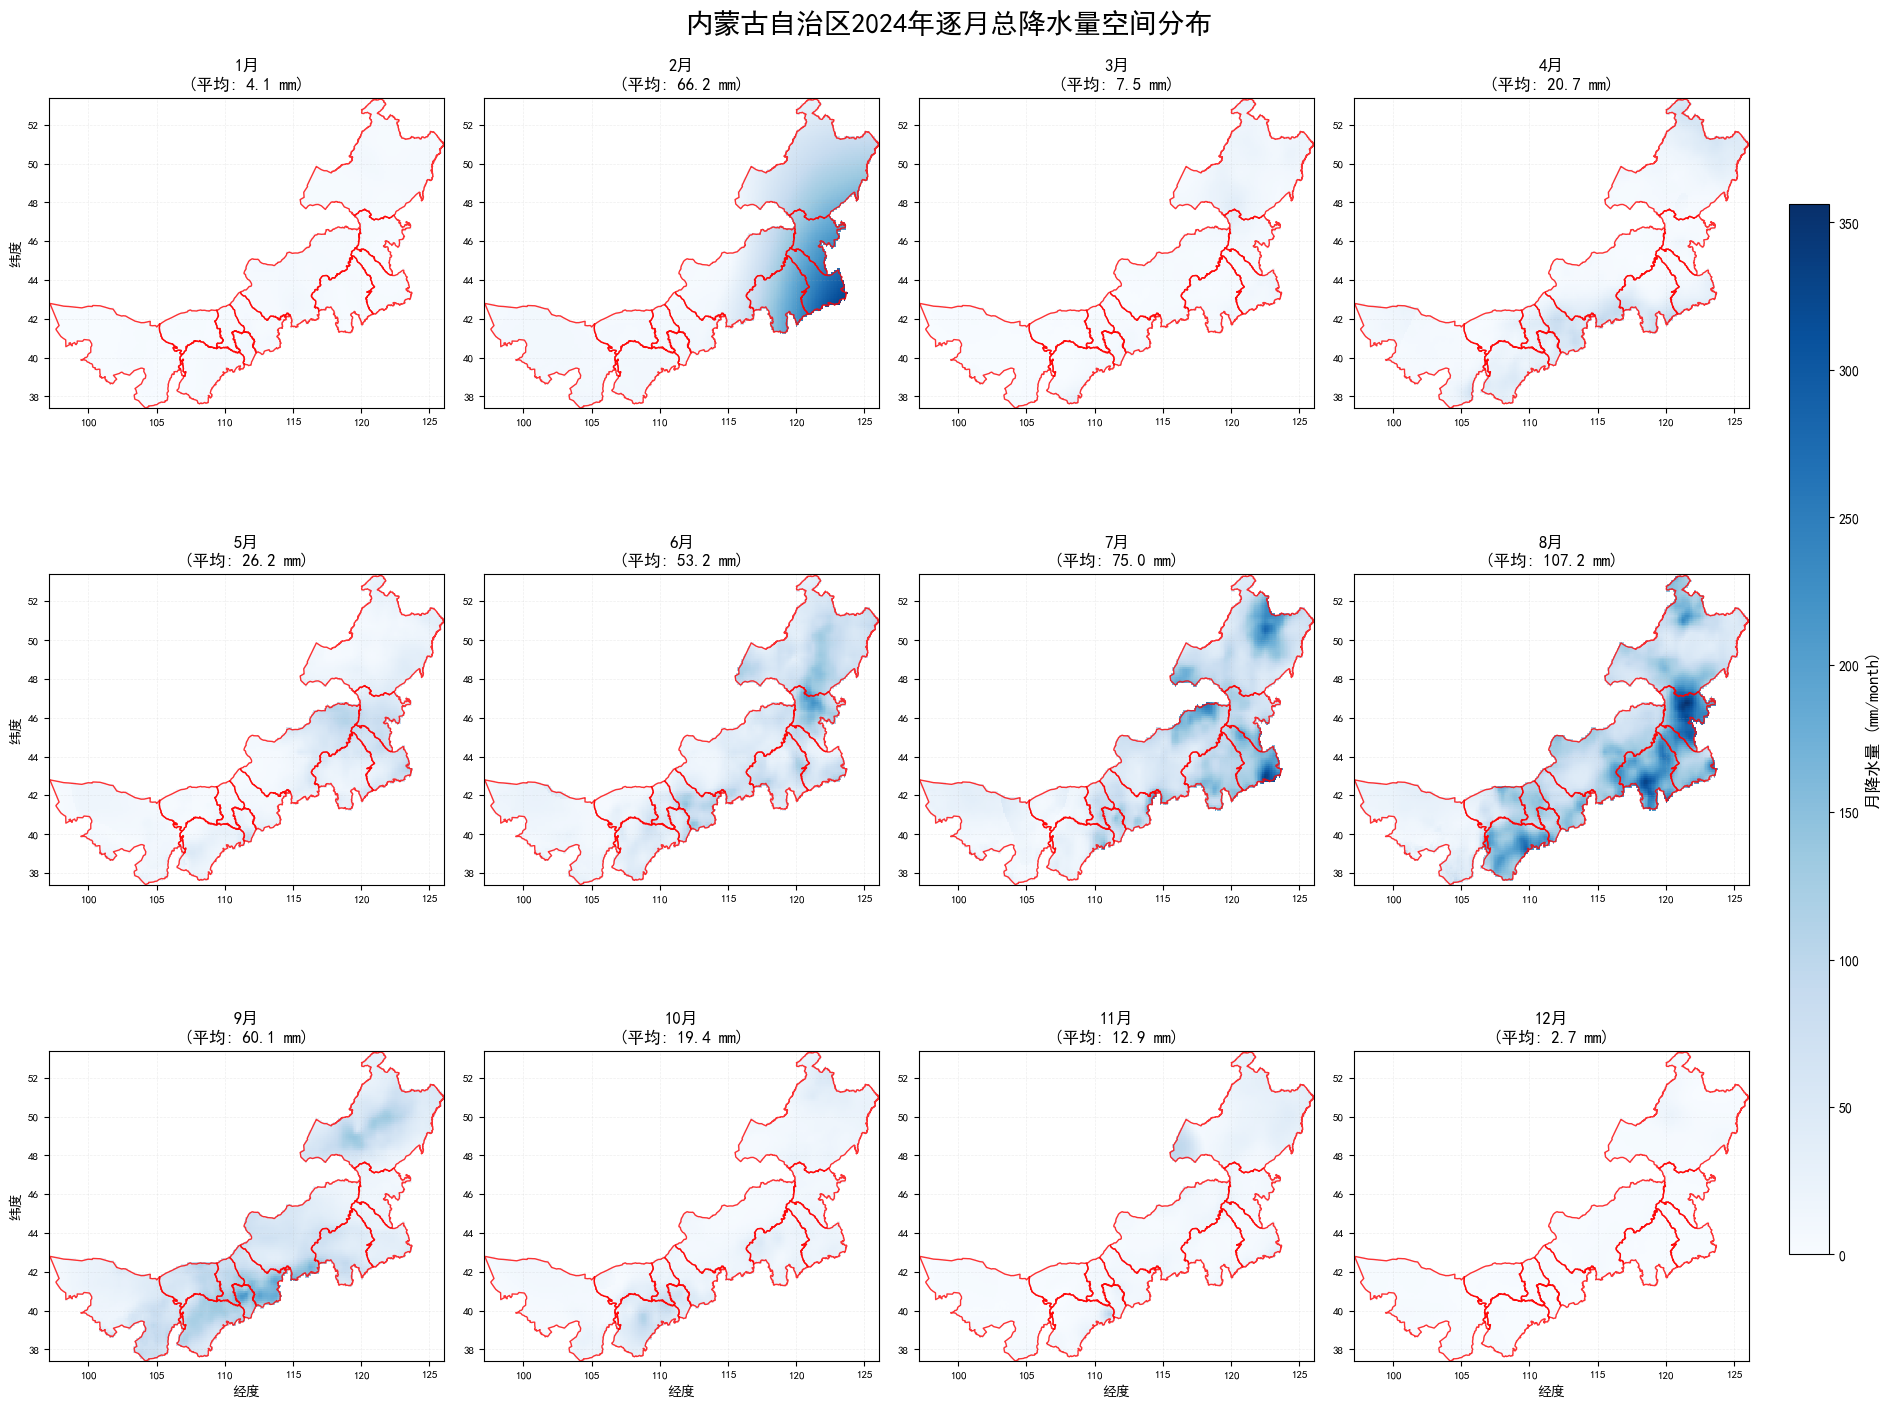


8. 绘制月降水量变化趋势图...
  ✓ 月降水量变化趋势图已保存: ./outputs/monthly/monthly_precipitation_trend.png


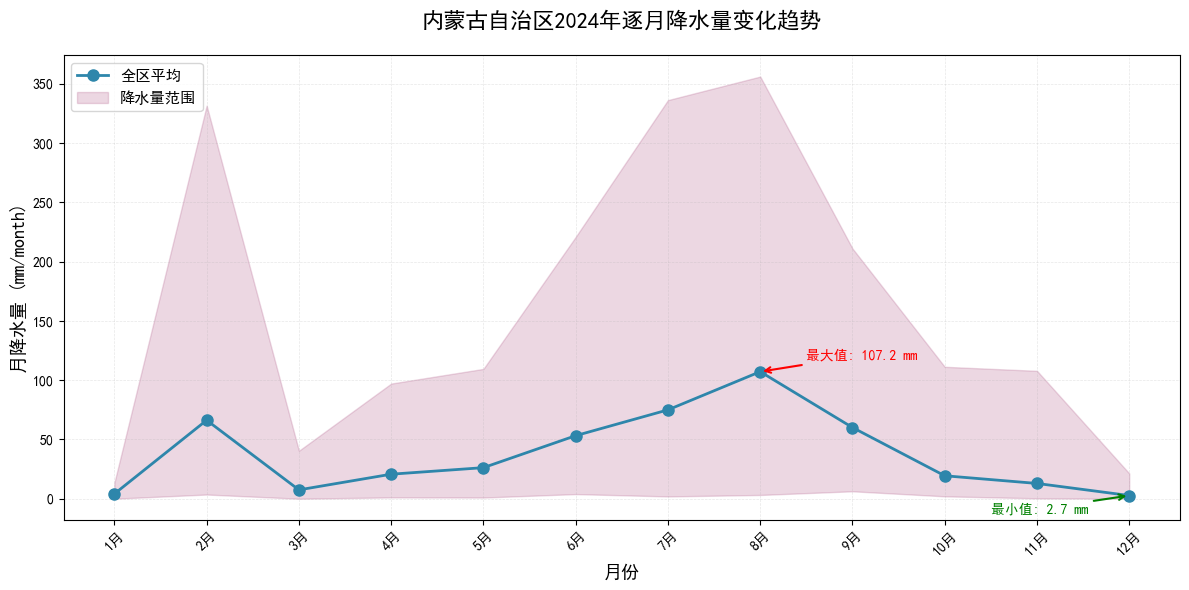


处理完成！

统计信息:
  年总降水量: 134.0 mm/year
  月平均降水量: 37.9 mm/month
  降水量最大月份: 8月 (107.2 mm)
  降水量最小月份: 12月 (2.7 mm)

输出文件:
  逐月数据:
    - ./outputs/monthly/Neimenggu_monthly_prec_2024.nc (所有月份)
    - ./outputs/monthly/Neimenggu_01_2024_prec.tif ~ 12_2024_prec.tif
  图形文件:
    - ./outputs/monthly/Neimenggu_monthly_precipitation_3x4.png (3x4分布图)
    - ./outputs/monthly/monthly_precipitation_trend.png (趋势图)

逐月降水量统计表:
--------------------------------------------------
月份       全区平均(mm)        最大值(mm)         最小值(mm)        
--------------------------------------------------
1月       4.1             13.5            0.0            
2月       66.2            331.6           3.5            
3月       7.5             40.5            0.0            
4月       20.7            97.1            1.1            
5月       26.2            109.5           1.0            
6月       53.2            220.8           3.9            
7月       75.0            336.3           1.9            
8月       107.2           356.1 

In [23]:
# 计算内蒙古自治区2024年逐月总降水量的空间分布情况
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np
import xarray as xr
import geopandas as gpd
import rioxarray
from pypinyin import lazy_pinyin
import os
import pandas as pd

# ============ 中文字体配置 ============
font_path = 'C:/Windows/Fonts/simhei.ttf'
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'SimHei'
plt.rcParams['axes.unicode_minus'] = False
print("✓ 中文字体配置成功: SimHei")

# 创建输出目录
os.makedirs("./outputs/monthly", exist_ok=True)

print("="*50)
print("计算内蒙古自治区2024年逐月总降水量")
print("="*50)

# -----------------------------
# 1. 读取矢量数据
# -----------------------------
print("\n1. 读取矢量数据...")
cities = gpd.read_file("./data/ChinaMap/cities.shp")
gdf_sel = cities[cities["省"] == "内蒙古自治区"]
print(f"  找到 {len(gdf_sel)} 个城市")

# -----------------------------
# 2. 读取降水NC文件
# -----------------------------
print("\n2. 读取降水数据...")
ds = xr.open_dataset("./data/CMFD/prec_CMFD_V0200_B-01_01dy_010deg_202401-202412.nc")

# 选择降水变量
da = ds["prec"]
print(f"  原始单位: {da.attrs.get('units', '未指定')}")
print(f"  时间范围: {da.time.values[0]} 到 {da.time.values[-1]}")

# -----------------------------
# 3. 单位转换并计算逐月总降水量
# -----------------------------
print("\n3. 计算2024年逐月总降水量...")

# 单位转换：kg m⁻² s⁻¹ → mm/day (乘以86400)
seconds_per_day = 24 * 3600
daily_precip = da * seconds_per_day

# 按月份分组计算月总降水量
monthly_total = daily_precip.groupby('time.month').sum(dim='time', skipna=True)
monthly_total.attrs['units'] = 'mm/month'
monthly_total.attrs['long_name'] = 'Monthly Total Precipitation'

# 设置CRS
monthly_total = monthly_total.rio.write_crs("EPSG:4326")

print(f"  月份数量: {len(monthly_total.month)}")
print(f"  月平均降水量: {monthly_total.mean(dim=['lat', 'lon']).values.mean():.1f} mm/month")

# -----------------------------
# 4. 坐标系统一
# -----------------------------
print("\n4. 坐标系统一...")
gdf_sel = gdf_sel.to_crs(monthly_total.rio.crs)

# -----------------------------
# 5. 裁剪内蒙古全区范围（逐月）
# -----------------------------
print("\n5. 裁剪内蒙古全区范围（逐月）...")
neimenggu_monthly = monthly_total.rio.clip(gdf_sel.geometry, all_touched=True)

# 保存逐月数据为NetCDF
print("\n6. 保存逐月数据...")
neimenggu_monthly.to_netcdf("./outputs/monthly/Neimenggu_monthly_prec_2024.nc")
print("  ✓ 逐月NetCDF已保存: ./outputs/monthly/Neimenggu_monthly_prec_2024.nc")

# 分别保存每个月的GeoTIFF
for month in range(1, 13):
    monthly_data = neimenggu_monthly.sel(month=month)
    tif_path = f"./outputs/monthly/Neimenggu_{month:02d}_2024_prec.tif"
    monthly_data.rio.to_raster(tif_path, dtype='float32')
print("  ✓ 各月GeoTIFF已保存")

# -----------------------------
# 7. 绘制3x4逐月分布图
# -----------------------------
print("\n7. 绘制3x4逐月降水量分布图...")

# 创建月份名称（中文）
month_names = ['1月', '2月', '3月', '4月', '5月', '6月',
               '7月', '8月', '9月', '10月', '11月', '12月']

# 创建图形，3行4列
fig, axes = plt.subplots(3, 4, figsize=(20, 15))
fig.suptitle('内蒙古自治区2024年逐月总降水量空间分布', fontsize=20, fontweight='bold', y=0.98)

# 计算统一的colorbar范围（所有月份共同的范围）
vmin = neimenggu_monthly.min().values
vmax = neimenggu_monthly.max().values
print(f"  统一色标范围: {vmin:.1f} - {vmax:.1f} mm/month")

# 存储各月平均降水量
monthly_means = []

# 遍历12个月
for month in range(1, 13):
    ax = axes[(month-1)//4, (month-1)%4]
    
    # 获取该月数据
    monthly_data = neimenggu_monthly.sel(month=month)
    monthly_mean = monthly_data.mean().values
    monthly_means.append(monthly_mean)
    
    # 绘制降水量分布
    im = monthly_data.plot(ax=ax, cmap='Blues', 
                          vmin=vmin, vmax=vmax,
                          add_colorbar=False,
                          add_labels=False)
    
    # 绘制内蒙古边界
    gdf_sel.boundary.plot(ax=ax, edgecolor='red', linewidth=1, facecolor='none', alpha=0.8)
    
    # 设置标题（包含月份和平均降水量）
    ax.set_title(f'{month_names[month-1]}\n(平均: {monthly_mean:.1f} mm)', 
                fontsize=12, fontweight='bold')
    
    # 设置坐标轴标签（只在外侧显示）
    if (month-1)//4 == 2:  # 最后一行
        ax.set_xlabel('经度', fontsize=10)
    else:
        ax.set_xlabel('')
    
    if (month-1)%4 == 0:  # 第一列
        ax.set_ylabel('纬度', fontsize=10)
    else:
        ax.set_ylabel('')
    
    # 添加网格（可选，透明度调低避免干扰）
    ax.grid(True, alpha=0.2, linestyle='--', linewidth=0.5)
    
    # 设置刻度标签字体大小
    ax.tick_params(labelsize=8)

# 添加统一的colorbar
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
cbar = plt.colorbar(im, cax=cbar_ax)
cbar.set_label('月降水量 (mm/month)', fontsize=12, fontweight='bold')
cbar.ax.tick_params(labelsize=10)

# 调整子图间距
plt.subplots_adjust(left=0.05, right=0.9, bottom=0.05, top=0.95, 
                    wspace=0.1, hspace=0.2)

# 保存图形
plt.savefig('./outputs/monthly/Neimenggu_monthly_precipitation_3x4.png', 
            dpi=300, bbox_inches='tight')
print("  ✓ 3x4逐月分布图已保存: ./outputs/monthly/Neimenggu_monthly_precipitation_3x4.png")
plt.show()

# -----------------------------
# 8. 绘制月降水量变化折线图
# -----------------------------
print("\n8. 绘制月降水量变化趋势图...")

fig2, ax2 = plt.subplots(figsize=(12, 6))

# 绘制全区平均月降水量变化
months = range(1, 13)
ax2.plot(months, monthly_means, marker='o', linewidth=2, markersize=8, 
        color='#2E86AB', label='全区平均')

# 添加最大最小值范围
monthly_max = []
monthly_min = []
for month in range(1, 13):
    monthly_data = neimenggu_monthly.sel(month=month)
    monthly_max.append(monthly_data.max().values)
    monthly_min.append(monthly_data.min().values)

# 填充范围
ax2.fill_between(months, monthly_min, monthly_max, alpha=0.2, color='#A23B72', label='降水量范围')

# 设置标题和标签
ax2.set_title('内蒙古自治区2024年逐月降水量变化趋势', fontsize=16, fontweight='bold', pad=20)
ax2.set_xlabel('月份', fontsize=13)
ax2.set_ylabel('月降水量 (mm/month)', fontsize=13)

# 设置x轴刻度
ax2.set_xticks(months)
ax2.set_xticklabels(month_names, rotation=45)

# 添加网格
ax2.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)

# 添加图例
ax2.legend(loc='upper left', fontsize=11)

# 标注最大值和最小值
max_month = np.argmax(monthly_means) + 1
min_month = np.argmin(monthly_means) + 1
max_value = max(monthly_means)
min_value = min(monthly_means)

ax2.annotate(f'最大值: {max_value:.1f} mm', 
            xy=(max_month, max_value), 
            xytext=(max_month+0.5, max_value+10),
            arrowprops=dict(arrowstyle='->', color='red', lw=1.5),
            fontsize=10, color='red')

ax2.annotate(f'最小值: {min_value:.1f} mm', 
            xy=(min_month, min_value), 
            xytext=(min_month-1.5, min_value-15),
            arrowprops=dict(arrowstyle='->', color='green', lw=1.5),
            fontsize=10, color='green')

plt.tight_layout()
plt.savefig('./outputs/monthly/monthly_precipitation_trend.png', dpi=300, bbox_inches='tight')
print("  ✓ 月降水量变化趋势图已保存: ./outputs/monthly/monthly_precipitation_trend.png")
plt.show()

# -----------------------------
# 9. 输出统计信息
# -----------------------------
print("\n" + "="*50)
print("处理完成！")
print("="*50)

print("\n统计信息:")
print(f"  年总降水量: {neimenggu_monthly.sum(dim='month').mean().values:.1f} mm/year")
print(f"  月平均降水量: {np.mean(monthly_means):.1f} mm/month")
print(f"  降水量最大月份: {month_names[np.argmax(monthly_means)]} ({max(monthly_means):.1f} mm)")
print(f"  降水量最小月份: {month_names[np.argmin(monthly_means)]} ({min(monthly_means):.1f} mm)")

print("\n输出文件:")
print("  逐月数据:")
print("    - ./outputs/monthly/Neimenggu_monthly_prec_2024.nc (所有月份)")
print("    - ./outputs/monthly/Neimenggu_01_2024_prec.tif ~ 12_2024_prec.tif")
print("  图形文件:")
print("    - ./outputs/monthly/Neimenggu_monthly_precipitation_3x4.png (3x4分布图)")
print("    - ./outputs/monthly/monthly_precipitation_trend.png (趋势图)")

# 打印逐月统计表
print("\n逐月降水量统计表:")
print("-" * 50)
print(f"{'月份':<8} {'全区平均(mm)':<15} {'最大值(mm)':<15} {'最小值(mm)':<15}")
print("-" * 50)
for month in range(12):
    print(f"{month_names[month]:<8} {monthly_means[month]:<15.1f} "
          f"{monthly_max[month]:<15.1f} {monthly_min[month]:<15.1f}")
print("-" * 50)

# 保存统计表为CSV
stats_df = pd.DataFrame({
    '月份': month_names,
    '全区平均降水量(mm)': monthly_means,
    '最大降水量(mm)': monthly_max,
    '最小降水量(mm)': monthly_min
})
stats_df.to_csv('./outputs/monthly/monthly_precipitation_statistics.csv', 
                index=False, encoding='utf-8-sig')
print("\n✓ 统计表已保存: ./outputs/monthly/monthly_precipitation_statistics.csv")
print("="*50)

In [ ]:
#利用clip方法得到内蒙古自治区内各个地市覆盖区域的降水数据，并分别保存为GeoTIFF和netCDF格式数据
#利用得到的nc数据，计算各个地市的年总降水量，并按照从低至高的顺序排序
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np
import xarray as xr
import geopandas as gpd
import rioxarray
from pypinyin import lazy_pinyin
import os
import pandas as pd

# ============ 中文字体配置 ============
font_path = 'C:/Windows/Fonts/simhei.ttf'
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'SimHei'
plt.rcParams['axes.unicode_minus'] = False
print("✓ 中文字体配置成功: SimHei")

# 创建输出目录
os.makedirs("./outputs/cities", exist_ok=True)

print("="*60)
print("内蒙古自治区各城市降水数据处理")
print("="*60)

# -----------------------------
# 1. 读取矢量数据
# -----------------------------
print("\n1. 读取矢量数据...")
cities = gpd.read_file("./data/ChinaMap/cities.shp")
gdf_sel = cities[cities["省"] == "内蒙古自治区"]
print(f"  找到 {len(gdf_sel)} 个城市")
print(f"  城市列表: {', '.join(gdf_sel['市'].values)}")

# -----------------------------
# 2. 读取降水NC文件
# -----------------------------
print("\n2. 读取降水数据...")
ds = xr.open_dataset("./data/CMFD/prec_CMFD_V0200_B-01_01dy_010deg_202401-202412.nc")

# 选择降水变量
da = ds["prec"]
print(f"  原始单位: {da.attrs.get('units', '未指定')}")
print(f"  时间范围: {da.time.values[0]} 到 {da.time.values[-1]}")

# -----------------------------
# 3. 单位转换并计算年总降水量
# -----------------------------
print("\n3. 计算2024年全年总降水量...")

# 单位转换：kg m⁻² s⁻¹ → mm/day (乘以86400)
seconds_per_day = 24 * 3600
daily_precip = da * seconds_per_day

# 沿时间维度求和，得到年总降水量 (mm/year)
annual_total = daily_precip.sum(dim='time', skipna=True)
annual_total.attrs['units'] = 'mm/year'
annual_total.attrs['long_name'] = 'Annual Total Precipitation'

print(f"  全区平均年降水量: {annual_total.mean().values:.1f} mm/year")
print(f"  年降水量范围: {annual_total.min().values:.1f} - {annual_total.max().values:.1f} mm/year")

# 设置CRS
annual_total = annual_total.rio.write_crs("EPSG:4326")

# -----------------------------
# 4. 坐标系统一
# -----------------------------
print("\n4. 坐标系统一...")
gdf_sel = gdf_sel.to_crs(annual_total.rio.crs)

# -----------------------------
# 5. 裁剪内蒙古全区范围
# -----------------------------
print("\n5. 裁剪内蒙古全区范围...")
neimenggu_total = annual_total.rio.clip(gdf_sel.geometry, all_touched=True)

# 保存全区数据
neimenggu_total.rio.to_raster("./outputs/Neimenggu_annual_prec_2024.tif", dtype='float32')
neimenggu_total.to_netcdf("./outputs/Neimenggu_annual_prec_2024.nc")
print("  ✓ 全区数据已保存")

# -----------------------------
# 6. 逐城市裁剪并保存（第一部分：保存GeoTIFF和NetCDF）
# -----------------------------
print("\n6. 逐城市裁剪并保存数据...")

# 存储城市降水量字典
city_precipitation = {}

for idx, city in enumerate(gdf_sel.itertuples(), 1):
    city_name = city.市
    geom = city.geometry
    
    print(f"\n  [{idx}/{len(gdf_sel)}] 处理: {city_name}")
    
    try:
        # 裁剪该城市的年总降水量数据
        clipped = neimenggu_total.rio.clip([geom], all_touched=True)
        
        # 检查裁剪后的数据是否有效
        if clipped.isnull().all():
            print(f"    ⚠️ 警告: 无有效数据")
            continue
        
        # 计算该城市的平均年降水量
        mean_precip = float(clipped.mean().values)
        city_precipitation[city_name] = mean_precip
        print(f"    平均年降水量: {mean_precip:.1f} mm/year")
        
        # 保存为GeoTIFF
        tif_path = f"./outputs/cities/{city_name}_annual_prec_2024.tif"
        clipped.rio.to_raster(tif_path, dtype='float32')
        print(f"    ✓ GeoTIFF: {tif_path}")
        
        # 保存为NetCDF
        city_name_safe = lazy_pinyin(city_name)
        city_name_safe = "_".join(city_name_safe)
        nc_path = f"./outputs/cities/{city_name_safe}_annual_prec_2024.nc"
        
        # 为NetCDF添加属性信息
        clipped.attrs['city_name'] = city_name
        clipped.attrs['units'] = 'mm/year'
        clipped.attrs['description'] = f'Annual total precipitation for {city_name}, Inner Mongolia, 2024'
        
        clipped.to_netcdf(nc_path)
        print(f"    ✓ NetCDF: {nc_path}")
        
    except Exception as e:
        print(f"    ✗ 错误: {str(e)}")

# -----------------------------
# 7. 排序（第二部分：从低到高排序）
# -----------------------------
print("\n" + "="*60)
print("各城市年总降水量排序（从低到高）")
print("="*60)

# 按降水量排序
sorted_cities = sorted(city_precipitation.items(), key=lambda x: x[1])

# 创建DataFrame
df_sorted = pd.DataFrame(sorted_cities, columns=['城市', '年降水量(mm/year)'])

# 显示排序结果
print("\n{:<12} {:>18}".format("城市", "年降水量(mm/year)"))
print("-" * 35)
for idx, (city, precip) in enumerate(sorted_cities, 1):
    print("{:<12} {:>18.1f}".format(city, precip))
print("-" * 35)
print("{:<12} {:>18.1f}".format("平均", df_sorted['年降水量(mm/year)'].mean()))
print("{:<12} {:>18.1f}".format("最大", df_sorted['年降水量(mm/year)'].max()))
print("{:<12} {:>18.1f}".format("最小", df_sorted['年降水量(mm/year)'].min()))

# -----------------------------
# 8. 保存排序结果
# -----------------------------
print("\n保存排序结果...")

# 保存为CSV
csv_path = "./outputs/cities_precipitation_sorted.csv"
df_sorted.to_csv(csv_path, index=False, encoding='utf-8-sig')
print(f"  ✓ CSV已保存: {csv_path}")

# 保存为Excel
try:
    excel_path = "./outputs/cities_precipitation_sorted.xlsx"
    df_sorted.to_excel(excel_path, index=False, engine='openpyxl')
    print(f"  ✓ Excel已保存: {excel_path}")
except:
    print("  提示: 如需Excel格式，请安装openpyxl: pip install openpyxl")

# -----------------------------
# 9. 输出文件列表
# -----------------------------
print("\n" + "="*60)
print("处理完成！输出文件汇总")
print("="*60)

print("\n1. 全区数据:")
print("   - ./outputs/Neimenggu_annual_prec_2024.tif")
print("   - ./outputs/Neimenggu_annual_prec_2024.nc")

print("\n2. 各城市数据 (GeoTIFF & NetCDF):")
for city in city_precipitation.keys():
    city_pinyin = "_".join(lazy_pinyin(city))
    print(f"   - ./outputs/cities/{city}_annual_prec_2024.tif")
    print(f"   - ./outputs/cities/{city_pinyin}_annual_prec_2024.nc")

print("\n3. 排序和分析结果:")
print("   - ./outputs/cities_precipitation_sorted.csv")
print("   - ./outputs/cities_precipitation_sorted.xlsx")
print("   - ./outputs/cities_precipitation_comparison.png")
print("   - ./outputs/cities_precipitation_summary.csv")

print("\n" + "="*60)


✓ 中文字体配置成功: SimHei
内蒙古自治区各城市降水数据处理

1. 读取矢量数据...
  找到 12 个城市
  城市列表: 兴安盟, 呼和浩特市, 包头市, 锡林郭勒盟, 乌海市, 赤峰市, 通辽市, 鄂尔多斯市, 阿拉善盟, 呼伦贝尔市, 巴彦淖尔市, 乌兰察布市

2. 读取降水数据...
  原始单位: kg m-2 s-1
  时间范围: 2024-01-01T10:30:00.000000000 到 2024-12-31T10:30:00.000000000

3. 计算2024年全年总降水量...
  全区平均年降水量: 749.0 mm/year
  年降水量范围: 0.0 - 8395.6 mm/year

4. 坐标系统一...

5. 裁剪内蒙古全区范围...
  ✓ 全区数据已保存

6. 逐城市裁剪并保存数据...

  [1/12] 处理: 兴安盟
    平均年降水量: 765.7 mm/year
    ✓ GeoTIFF: ./outputs/cities/兴安盟_annual_prec_2024.tif
    ✓ NetCDF: ./outputs/cities/xing_an_meng_annual_prec_2024.nc

  [2/12] 处理: 呼和浩特市
    平均年降水量: 584.2 mm/year
    ✓ GeoTIFF: ./outputs/cities/呼和浩特市_annual_prec_2024.tif
    ✓ NetCDF: ./outputs/cities/hu_he_hao_te_shi_annual_prec_2024.nc

  [3/12] 处理: 包头市
    平均年降水量: 442.0 mm/year
    ✓ GeoTIFF: ./outputs/cities/包头市_annual_prec_2024.tif
    ✓ NetCDF: ./outputs/cities/bao_tou_shi_annual_prec_2024.nc

  [4/12] 处理: 锡林郭勒盟
    平均年降水量: 417.2 mm/year
    ✓ GeoTIFF: ./outputs/cities/锡林郭勒盟_annual_prec_2024.tif
    ✓ NetCD